# Spotify Genre Classification 

## Setup and Imports

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sn
import matplotlib.pyplot as plt
from IPython.display import Image, display

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn import preprocessing
from sklearn.preprocessing import TargetEncoder, StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.inspection import permutation_importance
from sklearn.metrics.pairwise import euclidean_distances

from scipy.stats import loguniform, randint, uniform

# 1. Exploratory Data Analysis (EDA)

In [ ]:
# Load the dataset
DATA_PATH = 'Spotify_tracks_final.csv'
df = pd.read_csv(DATA_PATH, index_col=0)

print("Dataset columns:")
print(df.columns.tolist())

In [ ]:
# Aantal dubbele tracknamen berekenen
duplicates = df['track_name'].duplicated().sum()
print(f'Duplicates: {duplicates}')

# Dubbele tracks verwijderen, alle kolommen behouden
df = df.drop_duplicates(subset=['track_name', 'artist_name'], keep="first")

In [ ]:
# Unieke genres weergeven
print(f"Unique genres:\n{df['genre'].unique()}\n")

### Feature Analysis

Voor de eerste analyse kijken we naar de numerieke features.

In [ ]:
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
numeric_features

### Genre Similarity

In deze dataset zijn er enorm veel genres. Veel van deze genres lijken ook sterk op elkaar.
Een machine learning model zal dus redelijk wat problemen hebben bij het onderscheiden van bijvoorbeeld hard-rock en alt-rock.

In [ ]:
ROCK_GENRES = [
    "alt-rock",
    "alternative",
    "hard-rock",
    "rock",
    "punk",
    "punk-rock",
    "rock-n-roll",
    "rockabilly",
    "groove",
    "grunge",
    "goth",
    "hardcore",
    "psych-rock",
    "power-pop",
    "indie-rock",
    "emo",
    "j-rock",
    "guitar"
]

df_rock = df[df['genre'].isin(ROCK_GENRES)]
genre_means = df_rock.groupby('genre')[numeric_features].mean()

genre_scaled = StandardScaler().fit_transform(genre_means)

distance_matrix = euclidean_distances(genre_scaled)
distance_df = pd.DataFrame(distance_matrix,
                           index=genre_means.index,
                           columns=genre_means.index)

### Genre Similarity Heatmap

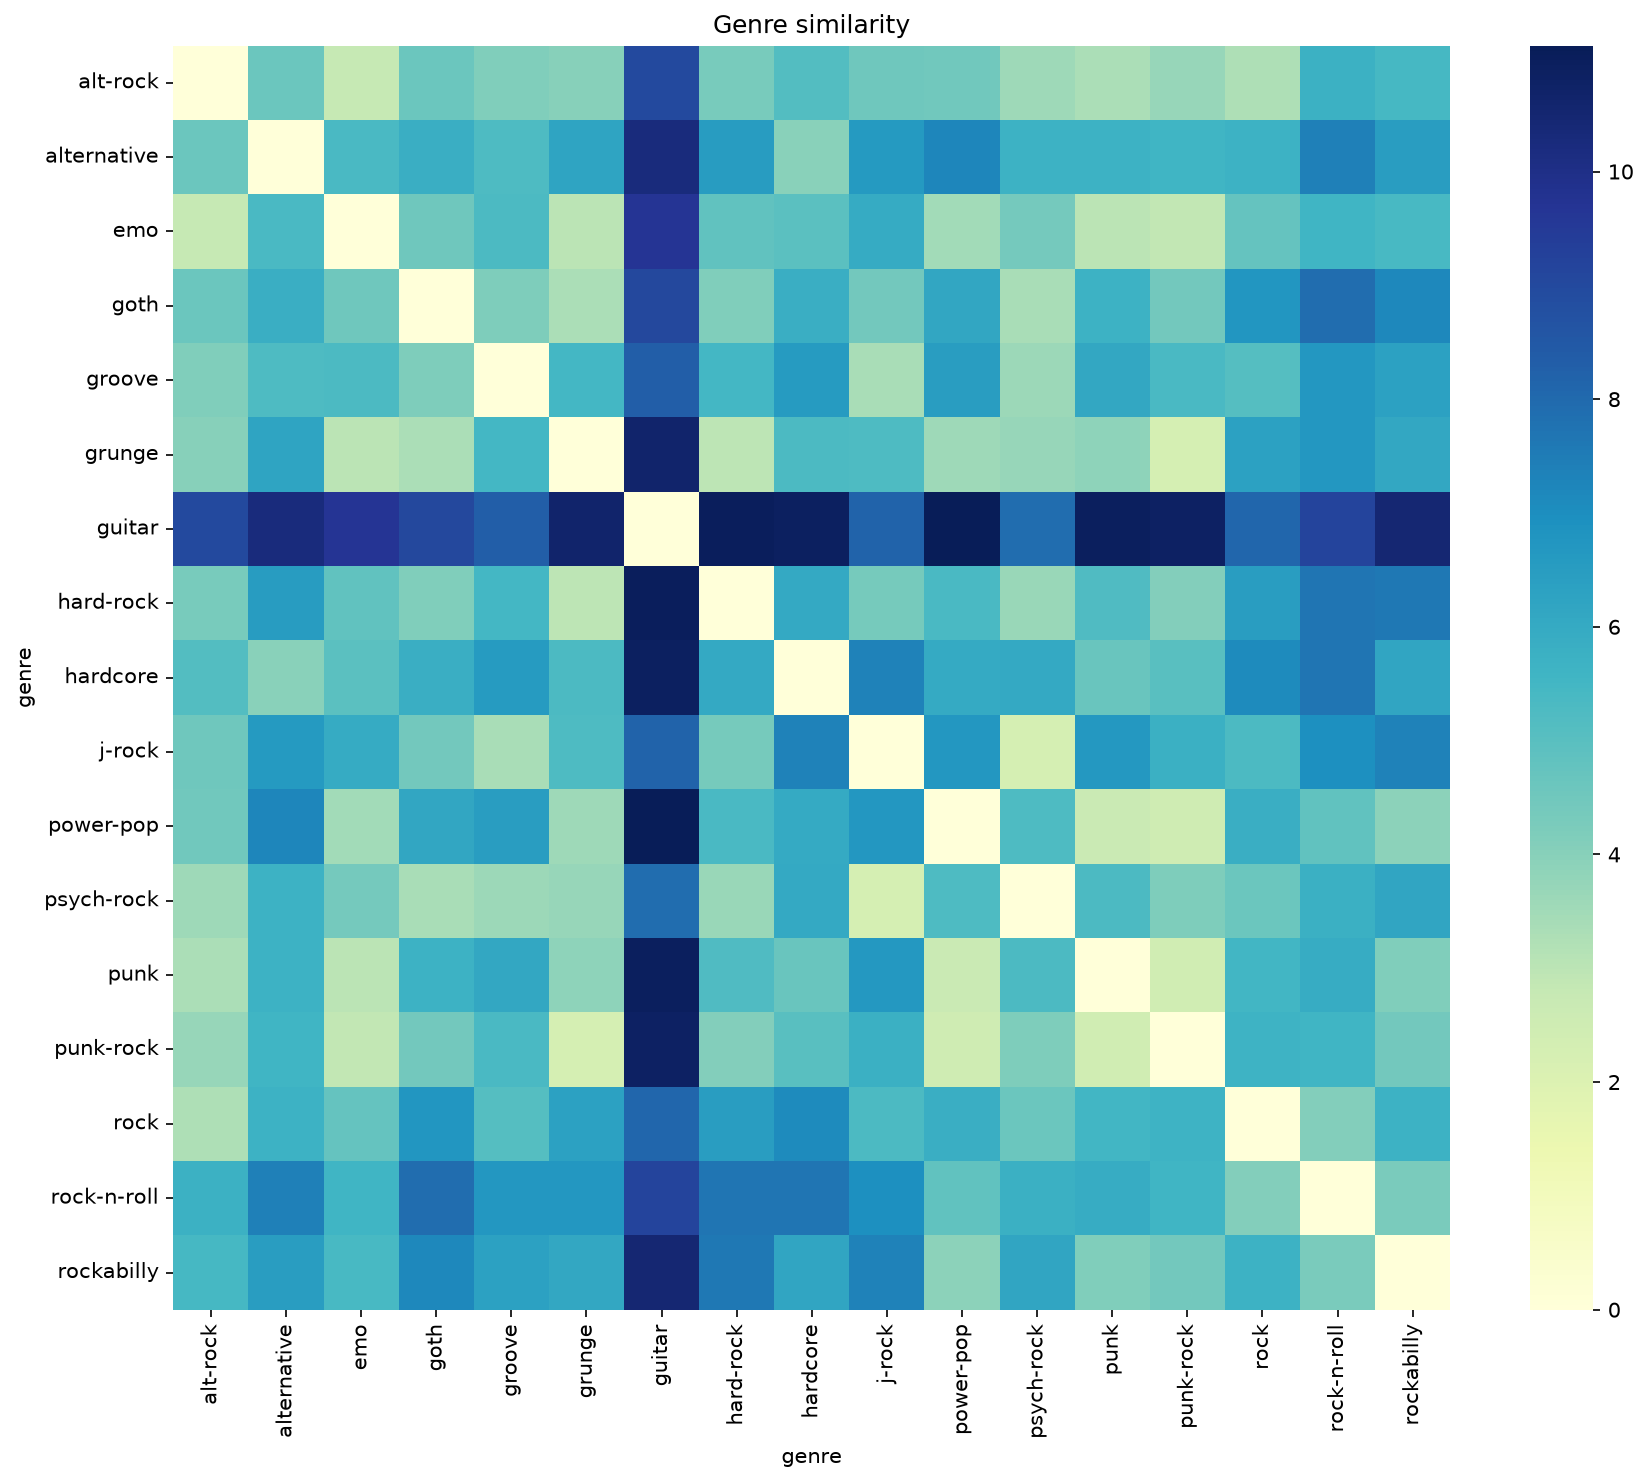



Buiten het donkerblauwe kruis op "guitar" zijn meeste genres binnen de rockfamilie redelijk gelijkaardig. Doordat er ook 116 verschillende genres zitten zal een ML model moeite hebben met zeer gelijkaardige genres van elkaar te onderscheiden. 

### Feature Correlation Analysis

Kolommen die verwijdert kunnen worden:
De eerste en meest duidelijke kolom die verwijderd kan worden zijn de verschillende tijdkolommen. Deze geven exact dezelfde waarden maar hebben gewoon een verschillende precisie.
Bijgevolg nemen we enkel duration_ms mee.

### Duration Features Correlation

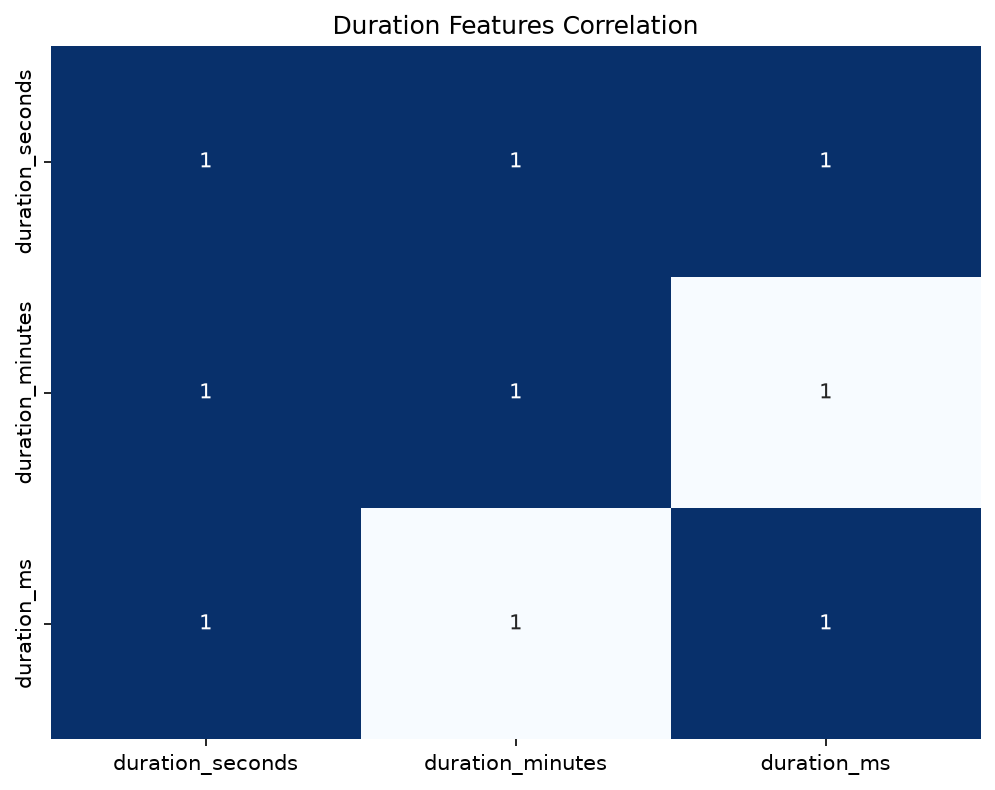



Andere kolommen die weg kunnen gelaten worden zijn kolommen die randinformatie geven over een track. Dit gaat dan bijvoorbeeld over de track name, de artist, uit welk album het kwam.
Deze gegevens zijn moeilijk om te zetten naar numerieke waarden. Hoewel een artist of een album duiding kan geven over uit welk genre het kwam, zal het model wellicht geen voorspellingen kunnen doen op basis van deze gegevens als het bv. een nieuw nog niet gekend album of artist tegenkomt.

Daarnaast kan de kolom database_shard_id verder ook weggelaten worden. Deze kolom is een database artifact en geeft geen gevolg op het genre. Gelijkaardig met preview_url. Dit is enkel een weburl en geeft geen impact op het genre.

Van numerieke features kunnen meeste behouden worden doordat deze een grote impact hebben op genre.

In [ ]:
CURRENT_FEATURES = ['popularity', 'duration_ms', 'explicit', 'acousticness', 'danceability', 'energy', 
                    'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 
                    'tempo', 'time_signature', 'valence']
SAMPLE_GENRES = ['Classical', 'hard-rock', 'blues', 'country', 'latin','funk','disco','electronic','pop']

df_sample = df[df['genre'].isin(SAMPLE_GENRES)]

genre_means = df_sample.groupby('genre')[CURRENT_FEATURES].mean()
genre_means_z = (genre_means - genre_means.mean()) / genre_means.std()

### Feature Means by Genre

In de gegeven grafiek lijkt er een goede spread over de verschillende genres over het gemiddelde van elke feature.
Een feature die weinig verschil toont is time_signature.
Samen met key en mode zijn dit geen ordinale waarde.
Key geeft de muzieknoot aan encoded in een nummer. Mode geeft dan aan of deze noot in major of minor is.
Deze kunnen zeker invloed hebben op het genre maar moeten geëncodeerd worden omdat dit geen ordinale waarden zijn.

### Feature Means per Genre

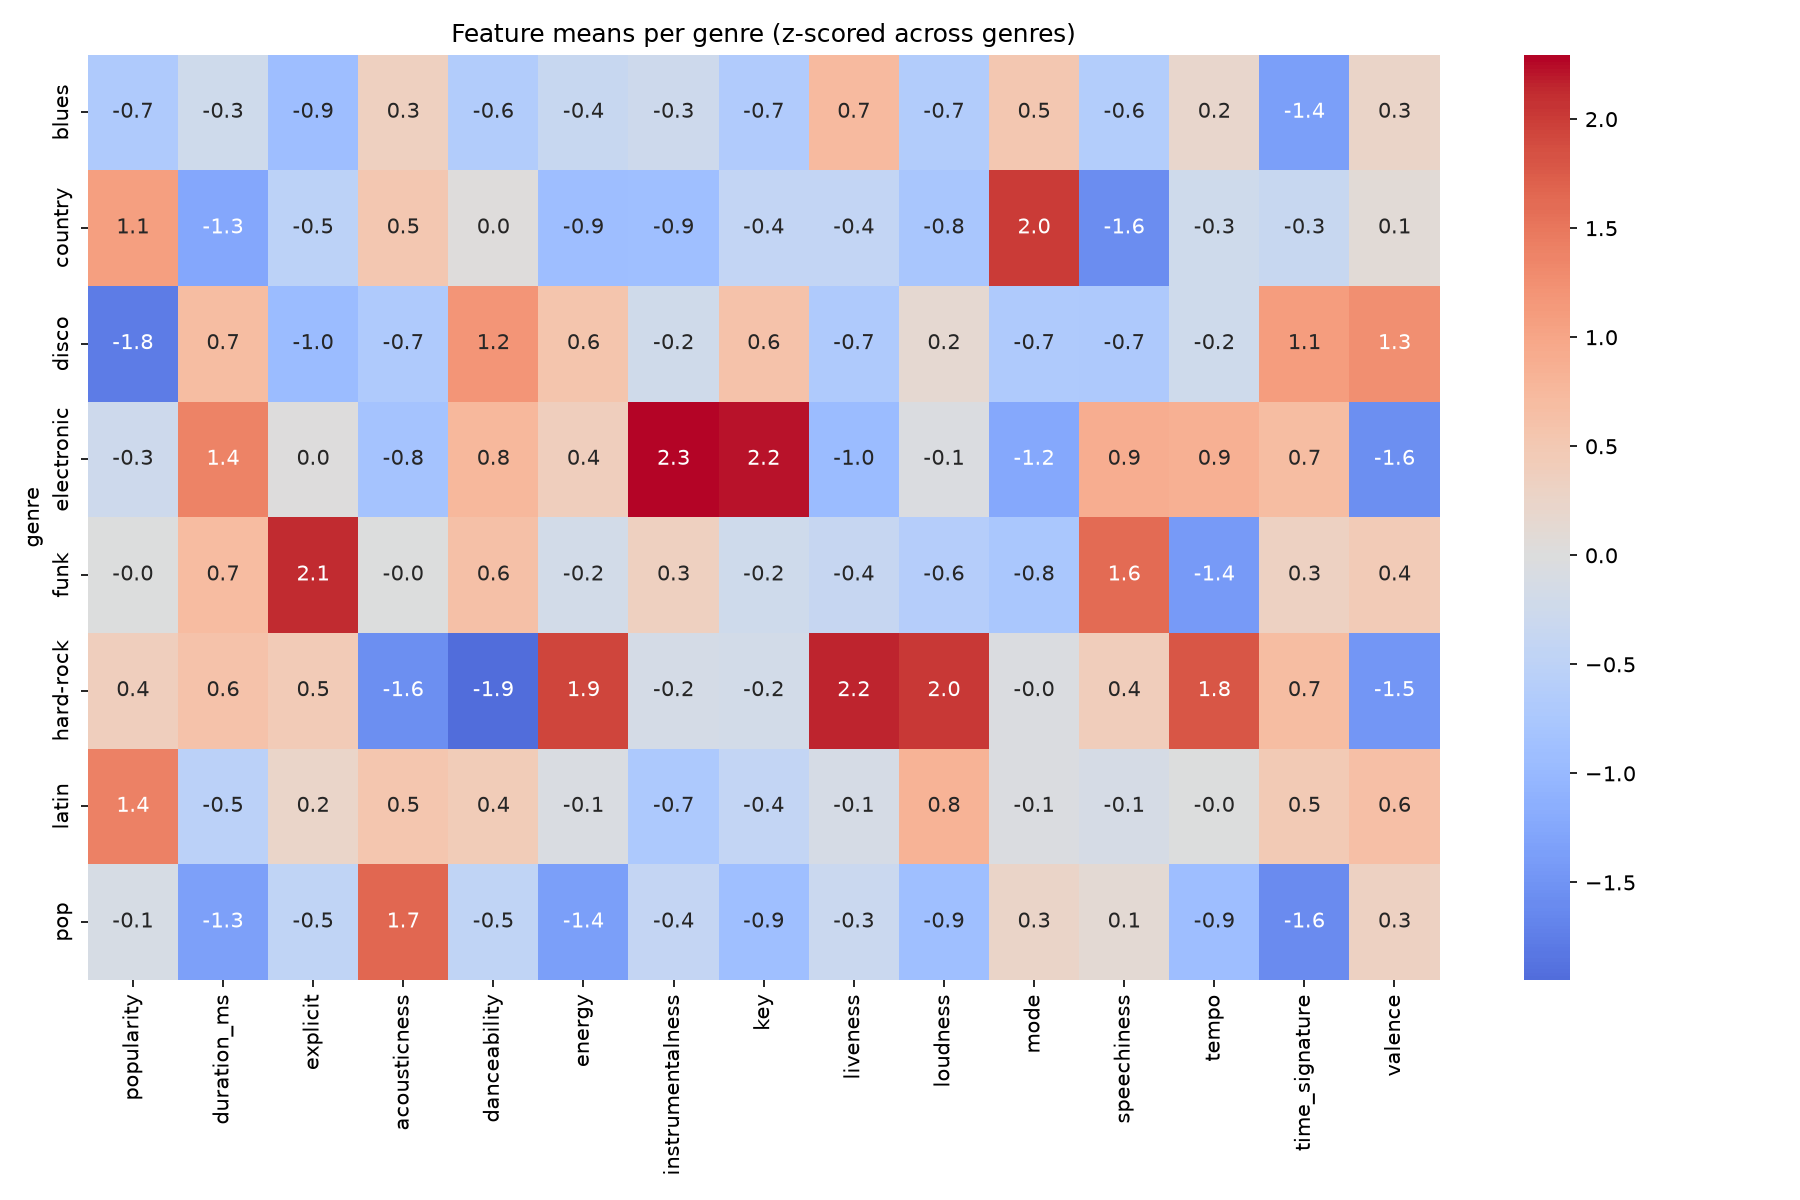



### Categorical Features Analysis

Key, mode, en time_signature zijn categorische features die geëncodeerd moeten worden. 

In [ ]:
CATEGORICAL_FEATURES = ['mode','key','time_signature']

plt.figure(figsize=(12, 4))
df_sample[CATEGORICAL_FEATURES].apply(lambda s: s.value_counts().sort_index()).plot(
    kind='bar', subplots=True, layout=(1,3), figsize=(12,4), legend=False)
plt.suptitle('Categorical Feature Distributions')
plt.tight_layout()
plt.savefig('./eda_visualisations/categorical_bars.png', dpi=150)
plt.close()

### Categorical Feature Distributions

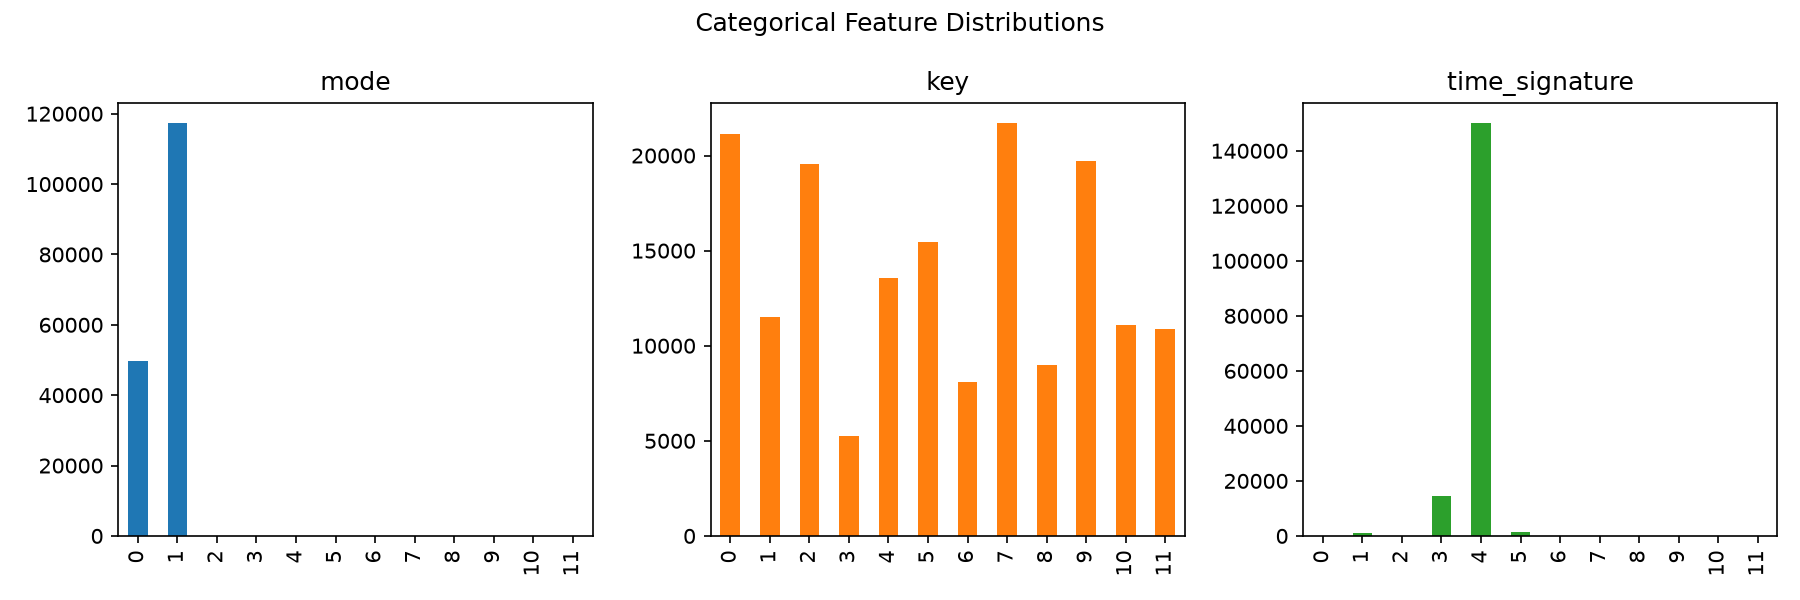



Zoals in deze grafiek kan gezien worden zijn mode en key over het algemeen redelijk wijd verspreid. time_signature aan de andere kant heeft de overgrote meerderheid op 4 met weinig variatie.
Doordat meeste tracks op time signature 4 bevinden zal het model wellicht geen goede voorspellingen kunnen maken op deze kolom. De waarden van mode en key kunnen wel behouden worden maar moeten geëncodeerd worden doordat er geen ordinaal verband is tussen verschillende muzieknoten

### Explicitness Analysis

Er zijn maar een heel klein aantal nummers die explicit zijn over de volledige dataset geconcentreerd onder enkele genres.Zoals gezien kan worden op onderstaande grafiek hebben sommige genres wel expleciete nummers, maar dit vertegenwoordigt dit een heel klein antal van alle nummers binnen het genre. Doordat we al genres samen gaan groeperen zal deze feature zijn nut snel verliezen. 

### Explicit Tracks by Genre (Stacked)

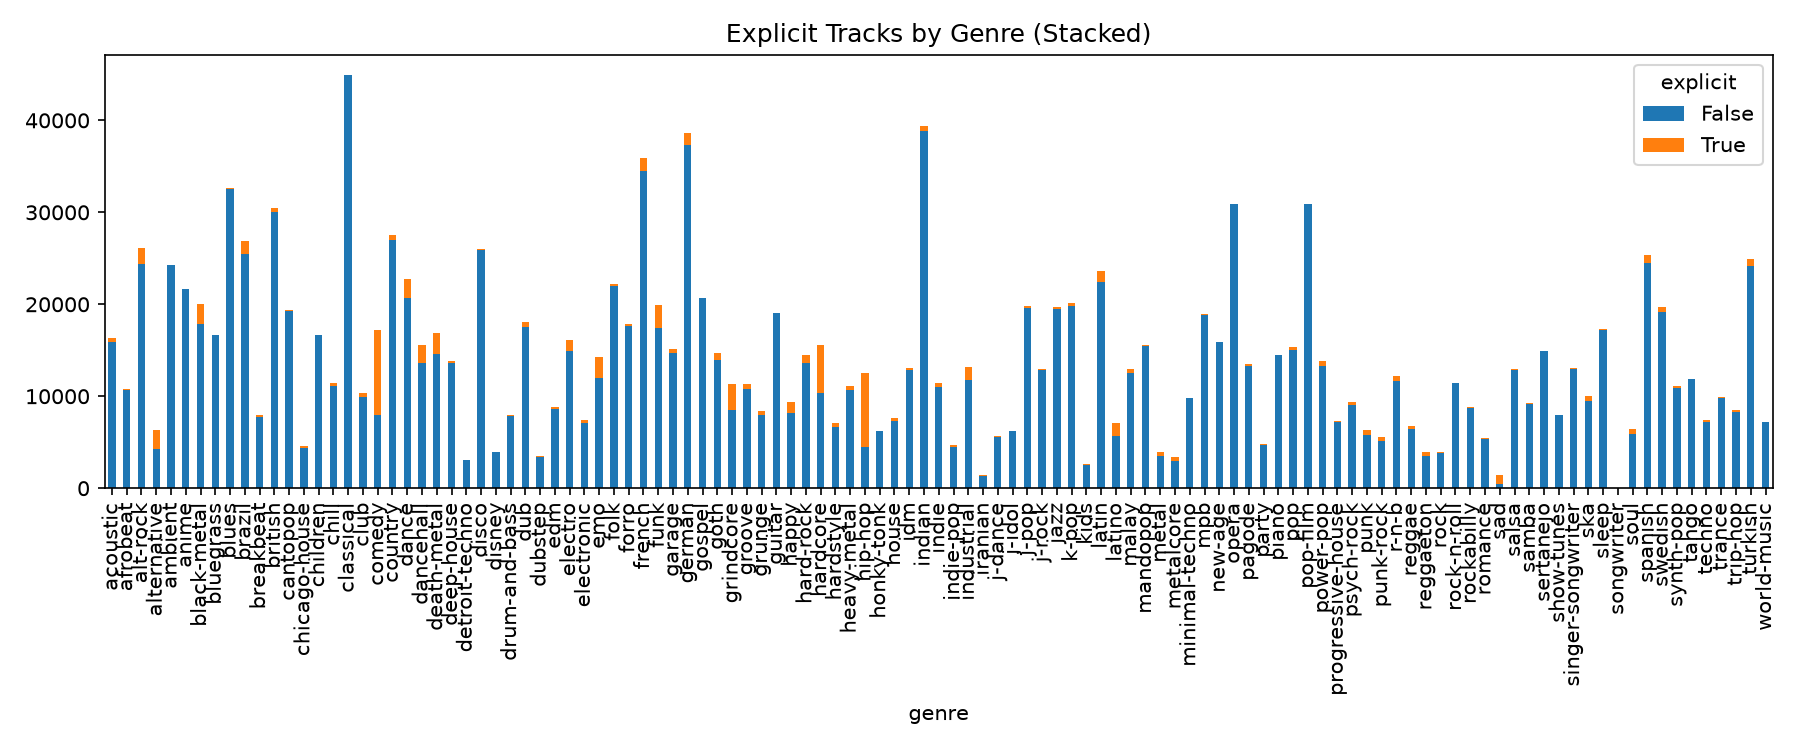



### Proportion of Explicit Tracks by Genre (Top 15)

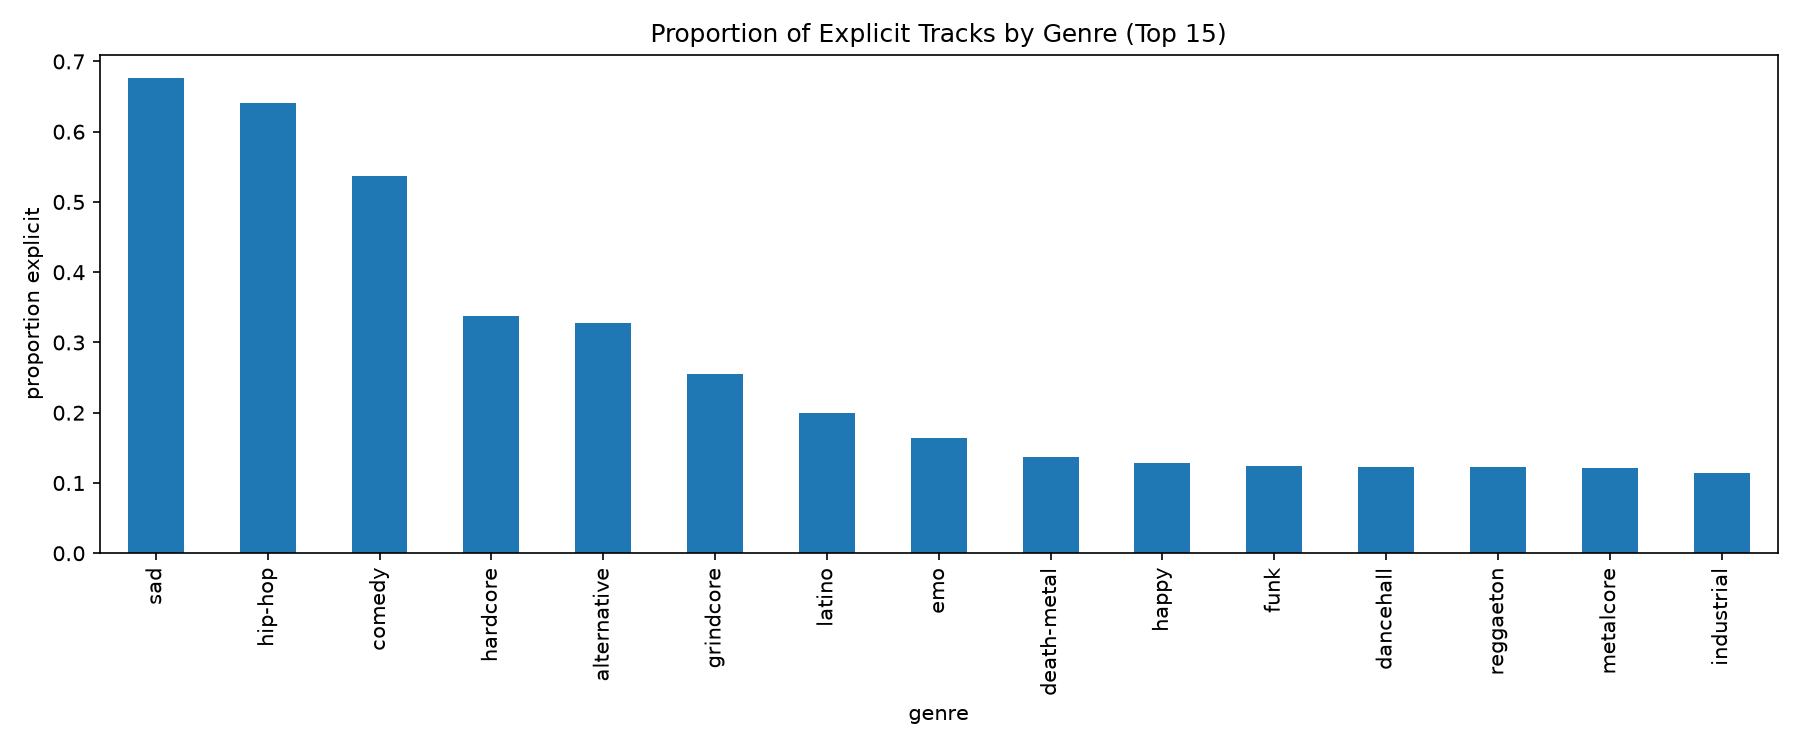



### Release Year Analysis

album_release_date:
De datum waarop een album is uitgebracht kan een impact hebben op het genre. Genres zoals jazz en funk zullen wellicht vaak oudere release dates hebben dan andere genres zoals rock.
Wellicht hebben we hier niet de volledige precisie voor nodig en volstaat het gewoon om het jaar op te geven.
Over het algemeen lijkt er wel een verband te zijn met wanneer de track uitgebracht werd en het genre. Pop bijvoorbeeld heeft het gemiddelde rond 1970.

### Release Year by Genre

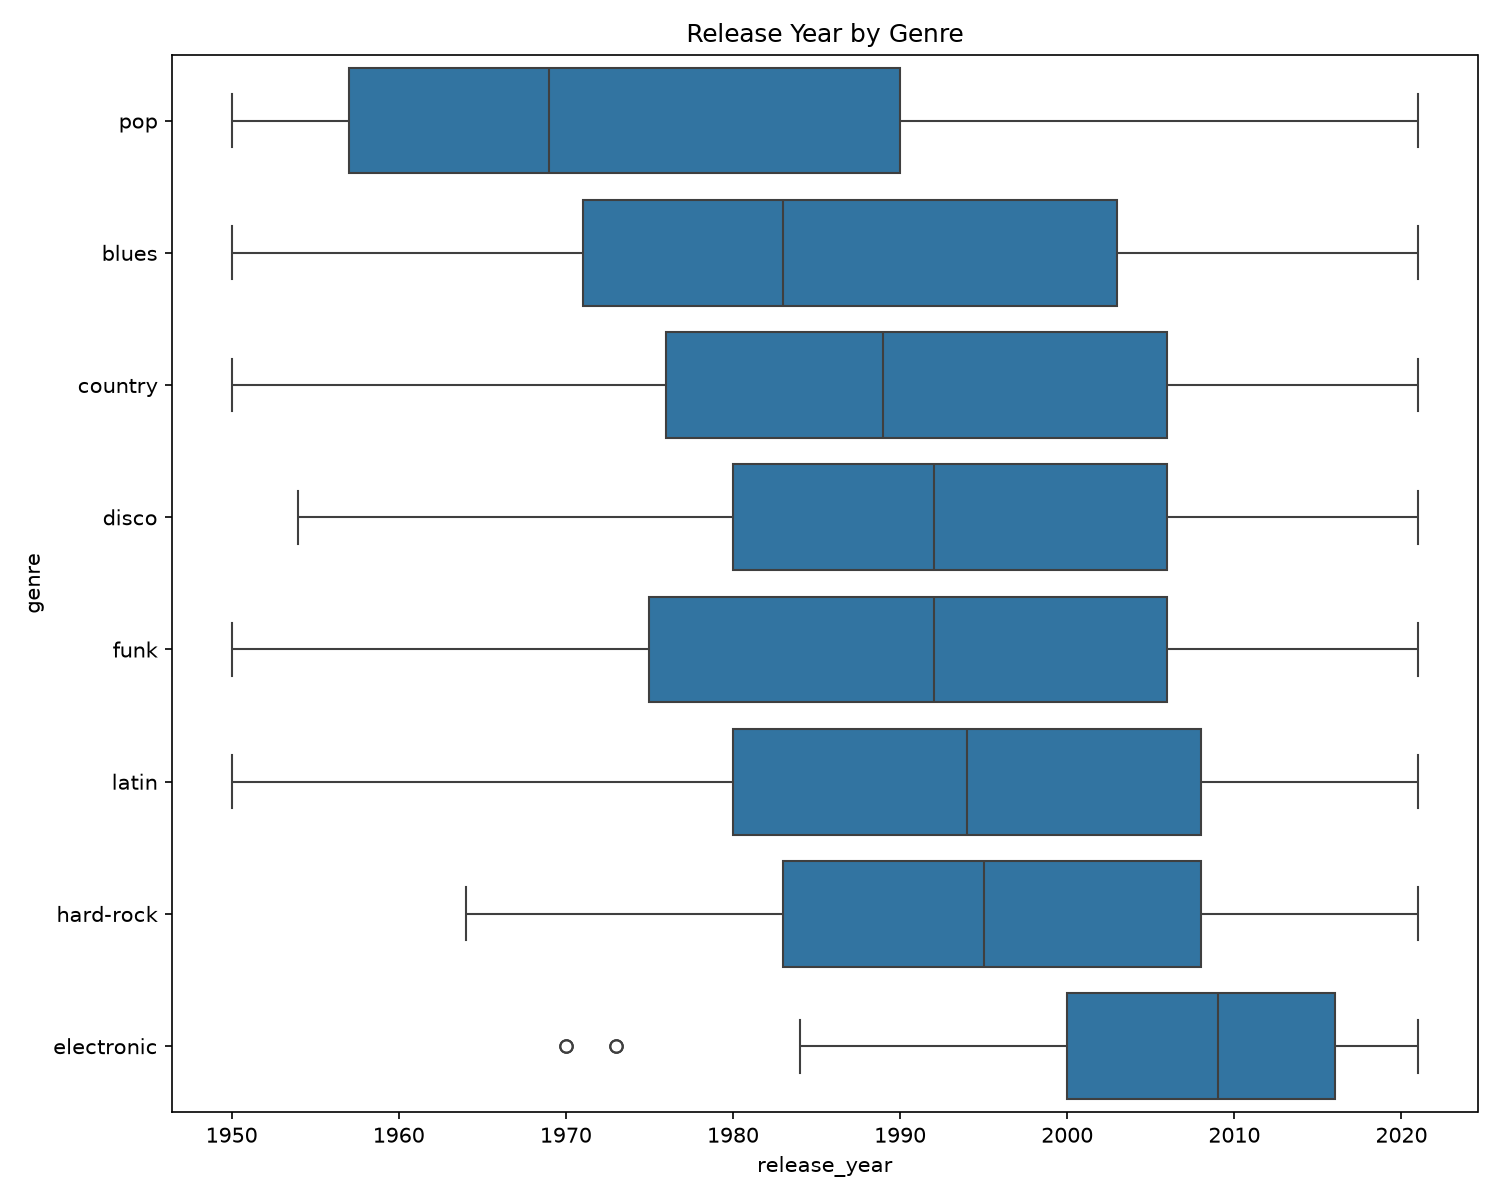



### Genre Grouping

Omdat de dataset enorm groot is en er per genre mogelijks maar enkele entries zijn is het best om deze te groeperen per genrefamilie.
De verdeling van genres is over het algemeen vrij subjectief en is er vaak overlap tussen verschillende groepen.
Over het algemeen worden genres gegroepeerd per 'familie' of in welk breder genre ze kunnen geplaatst worden.
De verschillende rock genres worden hier bv. onder Rock geplaatst.
Genres die geen overlappend genre hebben zoals Ambient werden hieruit weggelaten. Deze zouden te klein zijn in de dataset om er redelijke voorspellingen mee te maken.
De verschillende genres zoals "French" en "German" werden hier ook uit weggelaten. Deze vertegenwoordigen eerder het land waaruit ze komen. 

In [ ]:
# Define genre mapping for grouping
GENRE_MAPPING = {
    # Rock genres
    "alt-rock": "Rock",
    "alternative": "Rock",
    "hard-rock": "Rock",
    "rock": "Rock",
    "punk": "Rock",
    "punk-rock": "Rock",
    "rock-n-roll": "Rock",
    "rockabilly": "Rock",
    "groove": "Rock",
    "grunge": "Rock",
    "goth": "Rock",
    "hardcore": "Rock",
    "psych-rock": "Rock",
    "power-pop": "Rock",
    "indie-rock": "Rock",
    "emo": "Rock",
    "j-rock": "Rock",
    "guitar": "Rock",
    
    # Metal genres
    "metal": "Metal",
    "metalcore": "Metal",
    "death-metal": "Metal",
    "black-metal": "Metal",
    "grindcore": "Metal",
    
    # Pop genres
    "pop": "Pop",
    "indie-pop": "Pop",
    "synth-pop": "Pop",
    "k-pop": "Pop",
    "j-pop": "Pop",
    "j-idol": "Pop",
    "cantopop": "Pop",
    "mandopop": "Pop",
    "pop-film": "Pop",
    
    # Electronic genres
    "dance": "Electronic",
    "edm": "Electronic",
    "electronic": "Electronic",
    "house": "Electronic",
    "deep-house": "Electronic",
    "techno": "Electronic",
    "trance": "Electronic",
    "dubstep": "Electronic",
    "drum-and-bass": "Electronic",
    "breakbeat": "Electronic",
    "chicago-house": "Electronic",
    "detroit-techno": "Electronic",
    "minimal-techno": "Electronic",
    "progressive-house": "Electronic",
    "club": "Electronic",
    "dub": "Electronic",
    "idm": "Electronic",
    "hardstyle": "Electronic",
    
    # Hip-Hop/R&B genres
    "hip-hop": "Hip-Hop/R&B",
    "r-n-b": "Hip-Hop/R&B",
    "reggae": "Hip-Hop/R&B",
    "reggaeton": "Hip-Hop/R&B",
    "dancehall": "Hip-Hop/R&B",
    
    # Jazz/Blues genres
    "jazz": "Jazz/Blues",
    "blues": "Jazz/Blues",
    
    # Classical/Opera genres
    "classical": "Classical/Opera",
    "opera": "Classical/Opera",
    "piano": "Classical/Opera",
    "romance": "Classical/Opera",
    "show-tunes": "Classical/Opera",
    
    # Country/Folk genres
    "country": "Country/Folk",
    "folk": "Country/Folk",
    "bluegrass": "Country/Folk",
    "honky-tonk": "Country/Folk",
    "singer-songwriter": "Country/Folk",
    "songwriter": "Country/Folk",
    
    # Latin genres
    "latin": "Latin",
    "latino": "Latin",
    "salsa": "Latin",
    "samba": "Latin",
    "brazil": "Latin",
    "forro": "Latin",
    "mpb": "Latin",
    "pagode": "Latin",
    "sertanejo": "Latin",
    
    # Funk/Disco genres
    "funk": "Funk/Disco",
    "disco": "Funk/Disco",
}

# 2. Framework Setup

Gemeenschappelijke code tussen verschillende pipelines

In [ ]:
# Define constants
DATA_PATH = 'Spotify_tracks_final.csv'
TARGET = 'genre'
AUDIO_FEATURES = [
    "loudness", "acousticness", "energy", "instrumentalness",
    "danceability", "valence", "release_year", "duration_ms",
    "tempo", "liveness", "speechiness", "popularity", "mode", "key",
]

In [ ]:
def plot_confusion_matrix(y_true, y_pred, labels, out_path):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(10, 10))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False
    )
    fig.savefig(f"./confusion_matrices/{out_path}.png")
    plt.close(fig)
    return fig

In [ ]:
def evaluate(model, X_test, y_test, out_path):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.3f}")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Calculate permutation importances
    result = permutation_importance(
        model, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1
    )
    importances = pd.Series(result.importances_mean, index=X_test.columns)
    print("\nPermutation importances (test set):")
    print(importances.sort_values(ascending=False))
    
    # Generate confusion matrix
    plot_confusion_matrix(y_test, y_pred, model.classes_, out_path)
    
    return accuracy, importances

In [ ]:
def train_model(model, out_path, param_field):
    df = (
        pd.read_csv(DATA_PATH, index_col=0)
        .drop_duplicates(subset=["track_name", "artist_name"], keep="first")
        .assign(**{TARGET: lambda d: d[TARGET].map(GENRE_MAPPING)})
        .dropna(subset=[TARGET])
        .copy()
    )

    df["release_year"] = pd.to_datetime(
        df["album_release_date"], format="mixed", errors="coerce"
    ).dt.year

    y = df[TARGET]
    X = df[AUDIO_FEATURES]

    # Encoding van key. De waarde van mode moet niet encode worden want dit is al een binaire waarde.
    preprocess = ColumnTransformer(
        [("key_ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["key"])],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )

    # Split van 70 - 15 - 15 (train - val - test)
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X,
        y,
        test_size=0.15,
        stratify=y,
        random_state=42
    )
    # 0.15 / 0.85 = 0.17647...
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val,
        y_train_val,
        test_size=0.176,
        stratify=y_train_val,
        random_state=42
    )
    print(f"Dataset: {len(X)} samples ({len(X_train)} train, {len(X_test)} test, {len(X_val)} val)\n")

    # Pipeline voor het toepasssen van de encoding. Doet eerst encoding voor het model gegeven wordt.
    # Standard scaler: modellen zoals MLP en KNN zijn gevoellig aan niet-gestandardiseerde data. Features met grote schalen zullen domineren
    # tov kleinere features
    pipeline = Pipeline([
        ("preprocess", preprocess),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

    # Randomized tuning. Grid tuning over de volledige dataset zou te lang duren.
    # Cross validation over 5 folds. Trainset opgedeeld in 5 folds en telkens getest met gegeven parameters.
    # Wordt cross-validated met andere folds.
    gs = RandomizedSearchCV(
        estimator=pipeline, 
        cv=5, 
        param_distributions=param_field, 
        scoring="accuracy", 
        n_jobs=-1, 
        random_state=42, 
        refit=True
    )
    
    # Kleinere dataset voor sneller klaar te zijn
    idx = X_train.sample(n=100000, random_state=42).index
    gs.fit(X_train.loc[idx], y_train.loc[idx])
    print(gs.best_params_, gs.best_score_)
    
    best_model = gs.best_estimator_
    validation_accuracy = best_model.score(X_val, y_val)
    print(f"Validation accuracy: {validation_accuracy}")

    # Train on full training set and evaluate
    best_model.fit(X_train, y_train)
    return best_model, X_test, y_test, out_path

# 3. Models


## 3.1 HistGradientBoosting Classifier

Waarom histgradientboosting?
Decision trees zijn een goede manier om de gegeven features te classificeren. Een genre hangt sterk af van verschillende features.
Een genre bv met hoge energie, lage dansbaarheid en een recent release jaar kan eenvoudigt gemapt worden aan een decision tree.
Het model bouwt onderliggende de verschillende "beslissingen" die leiden naar een specifiek genre op. Bij voorspellingen maken kan dan door de flowchart gegaan worden tot het genre bereikt wordt.
Bij histgradientboosting worden telkens bomen opgebouwd die op elkaar itereren. Nieuwe decision trees leren telkens van de fouten uit vorige decision trees.
Op het einde hebben we dus vervolgens een decision tree die de som is van alle voorgaande decision trees.

In [ ]:
# Define parameter grid for HistGradientBoosting
HISTGRADIENT_PARAMS = {
    "model__learning_rate": loguniform(1e-2, 3e-1),
    "model__max_iter": randint(200, 800),
    "model__max_leaf_nodes": randint(15, 127),
    "model__max_depth": [None, 6, 10, 14],
    "model__min_samples_leaf": randint(5, 100),
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_bins": [127, 255],
}

def histgradient():
    model = HistGradientBoostingClassifier(
        min_samples_leaf=5,
        random_state=42
    )
    return model, HISTGRADIENT_PARAMS, "confusion_matrix_histgradientboost"

## 3.2 K-Nearest Neighbors Classifier

Bij KNN plotten we elk punt op een grafiek en kijken hoeveel x aantal van de dichtste buren gelijk zijn aan een specifiek genre.
Gelijkaardige genres zouden dicht bij elkaar moeten liggen op deze grafiek doordat ze gelijkaardige features hebben.
Een mogelijk probleem is overlap tussen genres. Door genres samen te groeperen zullen mogelijks genres die aan de rand staan van een bepaalde groep mogelijks mislabeled worden.

In [ ]:
# Define parameter grid for KNN
KNN_PARAMS = {
    "model__n_neighbors": randint(5, 100),
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],                      # Manhattan vs Euclidean
    "model__algorithm": ["auto", "ball_tree", "kd_tree"],
    "model__leaf_size": randint(20, 60),
}

def knn():
    model = KNeighborsClassifier(n_neighbors=30, n_jobs=-1)
    return model, KNN_PARAMS, "confusion_matrix_knn"

## 3.3 Multi-Layer Perceptron (Neural Network)

Neuraal netwerk. Neemt de verschillende audio features als input.
Door onderliggende de weights tussen de neurons aan te passen en gewichten toe te kennen kunnen de verschillende audio features door het netwerk gaan en vervolgens een voorspelling doen.
Gelijkaardig aan decision trees kan het model zo verbanden op te bouwen tussen verschillende features en hun genre.

In [ ]:
# Define parameter grid for MLP
MLP_PARAMS = {
    "model__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32), (256, 128), (64,)],
    "model__activation": ["relu", "tanh"],
    "model__alpha": loguniform(1e-5, 1e-1),
    "model__learning_rate_init": loguniform(1e-4, 1e-2),
    "model__batch_size": [128, 256, 512],
    "model__n_iter_no_change": [10, 20],
}

def mlp():
    model = MLPClassifier(
        hidden_layer_sizes=(64, 32), 
        max_iter=1000,
        early_stopping=True, 
        random_state=42
    )
    return model, MLP_PARAMS, "confusion_matrix_mlp"

In [ ]:
# Initialize models
print("=====Initializing Models=====")

# Get model definitions
hist_model, hist_params, hist_out = histgradient()
knn_model, knn_params, knn_out = knn()
mlp_model, mlp_params, mlp_out = mlp()

print("Models initialized successfully")

In [ ]:
# Note: Training all models may take a long time depending on your hardware.
# The following cells train each model separately.
# You can run them individually to save time.

# For demonstration purposes, we'll show the structure but note that
# actual training requires significant computational resources.

## 4.1 Train HistGradientBoosting Model

In [ ]:
print("=====HistGradientBoosting=====\n")

# Train the model
best_hist_model, X_test_hist, y_test_hist, _ = train_model(hist_model, hist_out, hist_params)

# Evaluate
hist_accuracy, hist_importances = evaluate(best_hist_model, X_test_hist, y_test_hist, hist_out)

## 4.2 Train KNN Model

In [ ]:
print("=====KNN=====\n")

# Train the model
best_knn_model, X_test_knn, y_test_knn, _ = train_model(knn_model, knn_out, knn_params)

# Evaluate
knn_accuracy, knn_importances = evaluate(best_knn_model, X_test_knn, y_test_knn, knn_out)

## 4.3 Train MLP Model

In [ ]:
print("=====MLP=====\n")

# Train the model
best_mlp_model, X_test_mlp, y_test_mlp, _ = train_model(mlp_model, mlp_out, mlp_params)

# Evaluate
mlp_accuracy, mlp_importances = evaluate(best_mlp_model, X_test_mlp, y_test_mlp, mlp_out)

## 5 Resultaat van training

### HistGradientBoosting Confusion Matrix

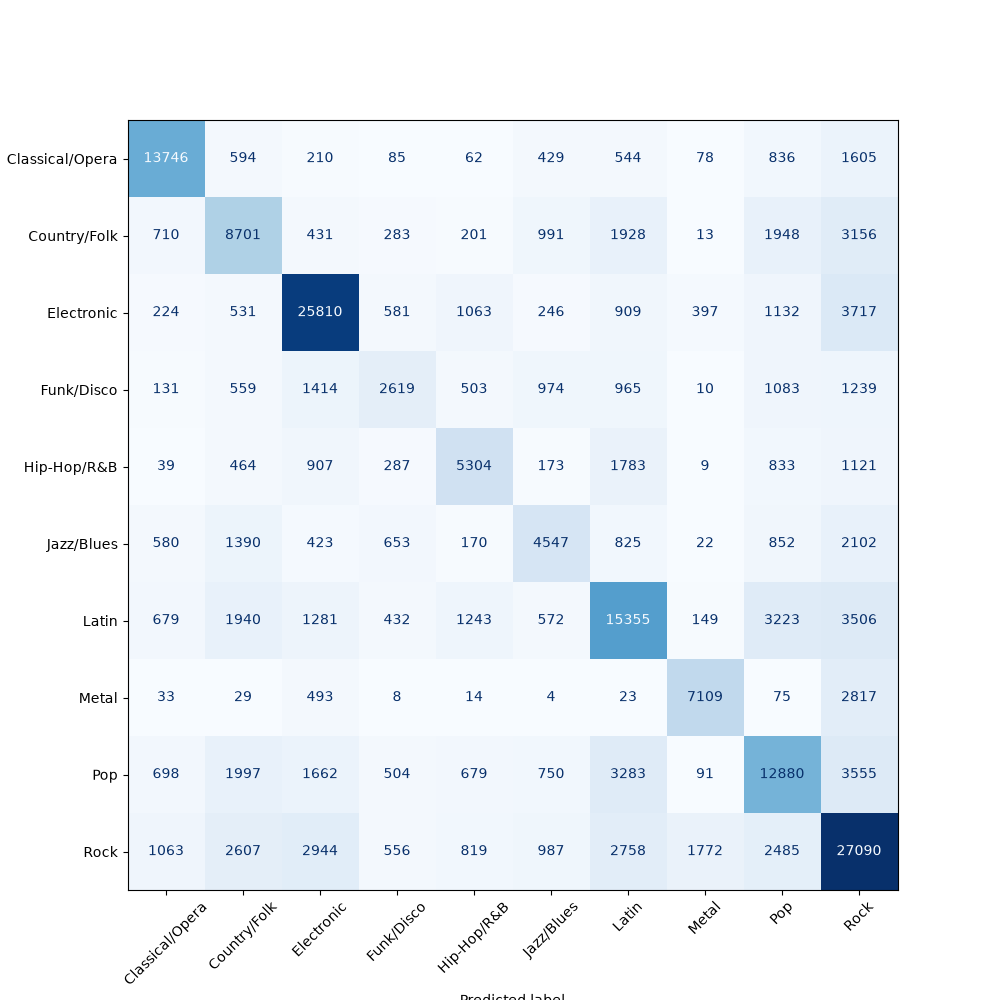



### Dataset
- Total samples: 1,408,709
- Training samples: 986,659
- Test samples: 211,307
- Validation samples: 210,743

### Best Hyperparameters
- L2 regularization: 0.006788
- Learning rate: 0.068954
- Maximum bins: 127
- Maximum depth: 10
- Maximum iterations: 601
- Maximum leaf nodes: 104
- Minimum samples per leaf: 48

### Model Performance
- Best cross-validation score: 0.5447
- Validation accuracy: 0.5474 (54.74%)
- Test accuracy: 0.583 (58.3%)

### Classification Report

| Genre | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Classical/Opera | 0.77 | 0.76 | 0.76 | 18,189 |
| Country/Folk | 0.46 | 0.47 | 0.47 | 18,362 |
| Electronic | 0.73 | 0.75 | 0.74 | 34,610 |
| Funk/Disco | 0.44 | 0.28 | 0.34 | 9,497 |
| Hip-Hop/R&B | 0.53 | 0.49 | 0.51 | 10,920 |
| Jazz/Blues | 0.47 | 0.39 | 0.43 | 11,564 |
| Latin | 0.54 | 0.54 | 0.54 | 28,380 |
| Metal | 0.74 | 0.67 | 0.70 | 10,605 |
| Pop | 0.51 | 0.49 | 0.50 | 26,099 |
| Rock | 0.54 | 0.63 | 0.58 | 43,081 |
| **Macro average** | **0.57** | **0.55** | **0.56** | |
| **Weighted average** | **0.58** | **0.58** | **0.58** | |

### Permutation Feature Importances

| Feature | Importance |
|---|---:|
| Acousticness | 0.138732 |
| Danceability | 0.111773 |
| Release year | 0.109235 |
| Instrumentalness | 0.085766 |
| Popularity | 0.072063 |
| Energy | 0.056272 |
| Valence | 0.050797 |
| Duration (ms) | 0.048694 |
| Speechiness | 0.045771 |
| Loudness | 0.041004 |
| Tempo | 0.027628 |
| Liveness | 0.012785 |
| Key | 0.007858 |
| Mode | 0.006828 |

Over het algemeen wordt er het best gescoord bij klassieke muziek. Klassieke muziek heeft een hoog uitgesproken acousticness waardoor het snel bepaald kan worden. Zoals getoond wordt in de permutations speelde acousticness de belangrijkste rol in het bepalen van een genre. Het model had het meest moeite met Funk/Disco. Dit komt waarschijnlijk door het feit dat Funk/Disco een klein deel van de dataset vertegenwoordigd. Country/Folk muziek werd het meest verkeerd bepaald als rockmuziek. Doordat we redelijk brede genres genomen hebben kan het zijn dat bepaalde genres binnen rock zoals indie redelijk dicht liggen bij folk/country muziek. Algemeen doet Histgradient het wel het best tussen alle modellen. Zoals eerder vermeld zijn boomstructuren een gepaste oplossing tot het voorspellen van muziekgenres op muziekdata. Het model kan snel door de decision tree gaan en beslissingen maken zoals "Hoge energie > hoge dansbaarheid > released in 1970" en op funk eindigen. Over het algemeen zou ik wel zeggen dat dit een goede performance is. 

### KNN Confusion Matrix

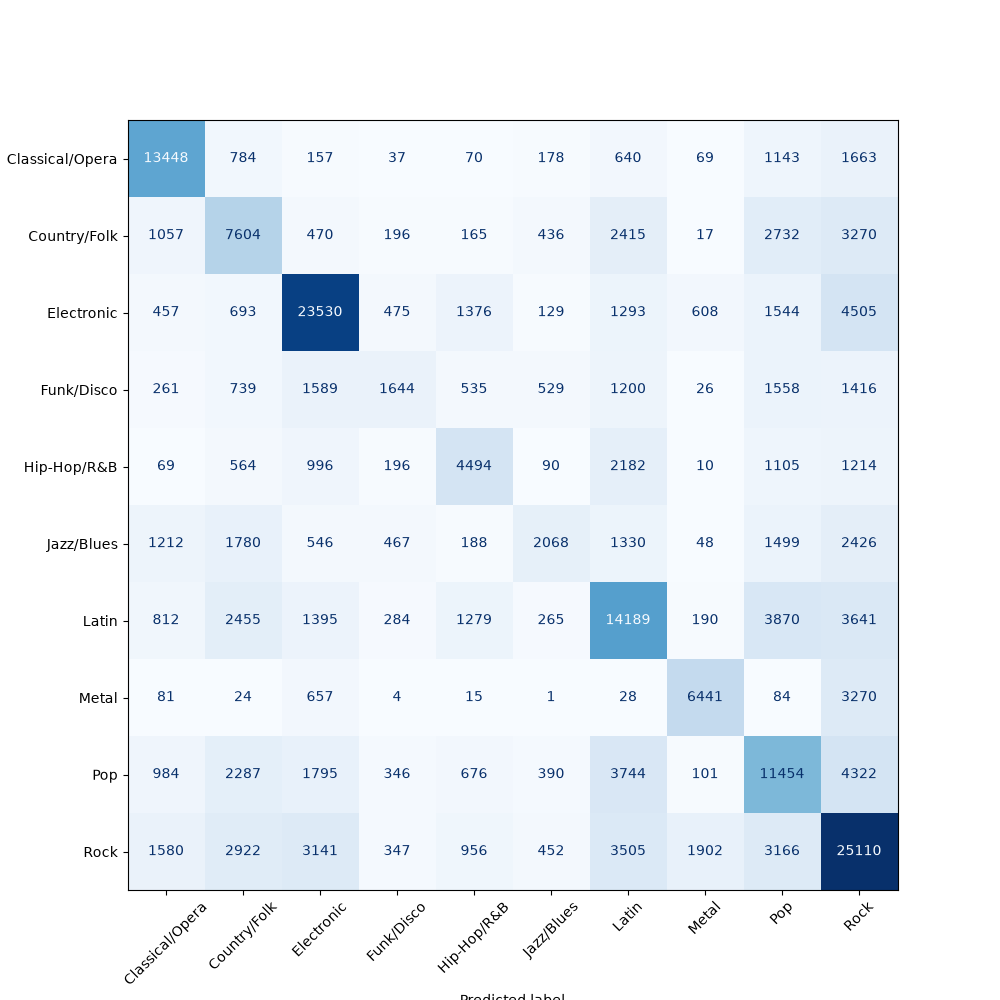



## KNN Model

### Dataset
- Total samples: 1,408,709
- Training samples: 986,659
- Test samples: 211,307
- Validation samples: 210,743

### Best Hyperparameters
- Algorithm: kd_tree
- Leaf size: 43
- Number of neighbors: 28
- Distance metric parameter (p): 1 (Manhattan distance)
- Weights: distance

### Model Performance
- Best cross-validation score: 0.47639
- Validation accuracy: 0.4803 (48.03%)
- Test accuracy: 0.520 (52.0%)

### Classification Report

| Genre | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Classical/Opera | 0.67 | 0.74 | 0.71 | 18,189 |
| Country/Folk | 0.38 | 0.41 | 0.40 | 18,362 |
| Electronic | 0.69 | 0.68 | 0.68 | 34,610 |
| Funk/Disco | 0.41 | 0.17 | 0.24 | 9,497 |
| Hip-Hop/R&B | 0.46 | 0.41 | 0.43 | 10,920 |
| Jazz/Blues | 0.46 | 0.18 | 0.26 | 11,564 |
| Latin | 0.46 | 0.50 | 0.48 | 28,380 |
| Metal | 0.68 | 0.61 | 0.64 | 10,605 |
| Pop | 0.41 | 0.44 | 0.42 | 26,099 |
| Rock | 0.49 | 0.58 | 0.53 | 43,081 |
| **Macro average** | **0.51** | **0.47** | **0.48** | |
| **Weighted average** | **0.52** | **0.52** | **0.51** | |

De accuraatheid van KNN ligt een stuk lager dan bij Histgradient. Dit komt waarschijnlijk doordat we redelijk veel genres samengevoegd hebben. Genres die aan de rand van hun cluster liggen zullen verkeerd geclassificeerd worden. Dit kan duidelijk gezien worden aan de confusion matrix, waar meerdere rock tracks verkeerd geclassificeerd worden. Meerdere andere genres vallen ook verkeerd binnen rock. Dit kan zijn omdat de groep net iets te breed genomen werd voor KNN. Hier kunnen we wederom zien dat de accuraatheid het hoogst ligt bij Classical/Opera en Funk/Disco het slechtst doen. 

### MLP Confusion Matrix

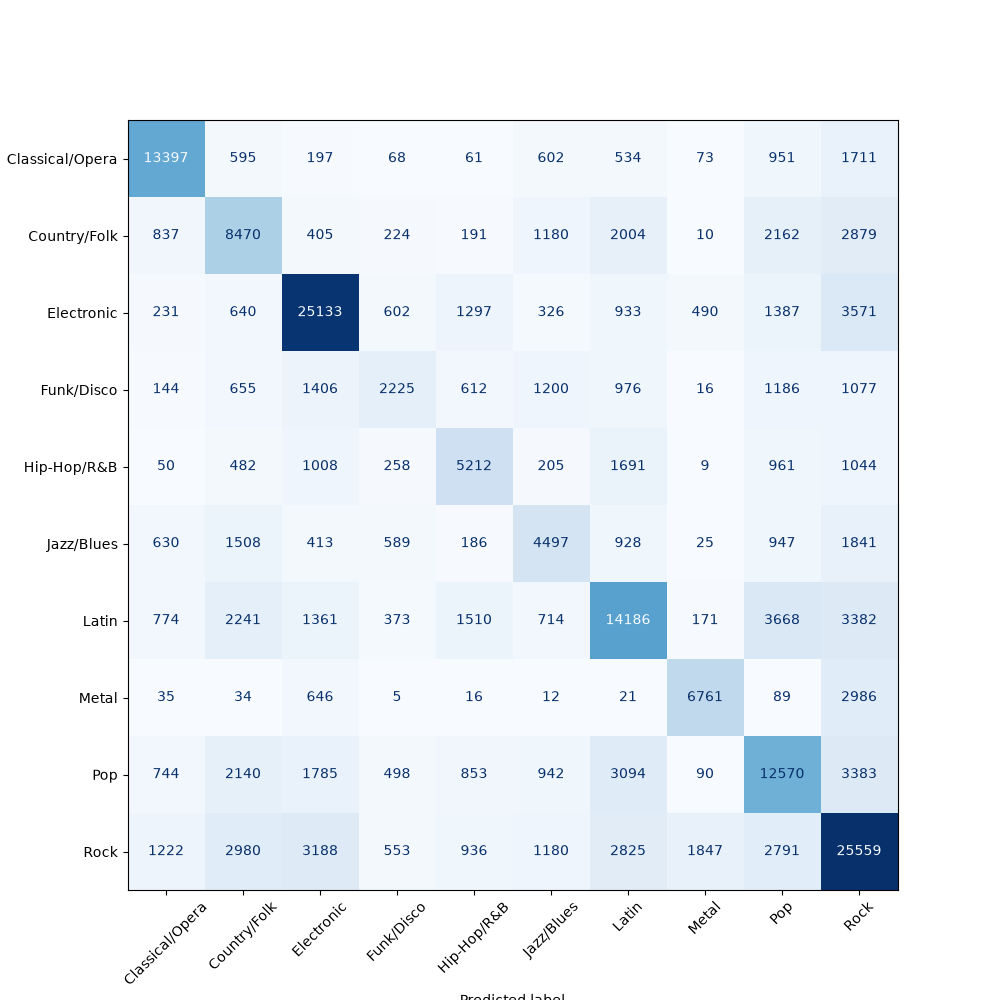



## MLP Model

### Dataset
- Total samples: 1,408,709
- Training samples: 986,659
- Test samples: 211,307
- Validation samples: 210,743

### Best Hyperparameters
- Activation function: tanh
- Alpha (L2 regularization): 0.000147
- Batch size: 512
- Hidden layer sizes: (128, 64, 32)
- Initial learning rate: 0.000582
- Early stopping patience: 20 iterations

### Model Performance
- Best cross-validation score: 0.51871
- Validation accuracy: 0.5206 (52.06%)
- Test accuracy: 0.558 (55.8%)

### Classification Report

| Genre | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Classical/Opera | 0.74 | 0.74 | 0.74 | 18,189 |
| Country/Folk | 0.43 | 0.46 | 0.44 | 18,362 |
| Electronic | 0.71 | 0.73 | 0.72 | 34,610 |
| Funk/Disco | 0.41 | 0.23 | 0.30 | 9,497 |
| Hip-Hop/R&B | 0.48 | 0.48 | 0.48 | 10,920 |
| Jazz/Blues | 0.41 | 0.39 | 0.40 | 11,564 |
| Latin | 0.52 | 0.50 | 0.51 | 28,380 |
| Metal | 0.71 | 0.64 | 0.67 | 10,605 |
| Pop | 0.47 | 0.48 | 0.48 | 26,099 |
| Rock | 0.54 | 0.59 | 0.56 | 43,081 |
| **Macro average** | **0.54** | **0.52** | **0.53** | |
| **Weighted average** | **0.56** | **0.56** | **0.56** | |

### Permutation Feature Importances

| Feature | Importance |
|---|---:|
| Danceability | 0.120075 |
| Acousticness | 0.119953 |
| Release year | 0.101519 |
| Energy | 0.098370 |
| Popularity | 0.067623 |
| Instrumentalness | 0.064050 |
| Valence | 0.059790 |
| Loudness | 0.057145 |
| Duration (ms) | 0.048971 |
| Speechiness | 0.046733 |
| Tempo | 0.025397 |
| Liveness | 0.011189 |
| Key | 0.008880 |
| Mode | 0.007087 |

Beter dan KNN maar net iets minder dan Histgradient. In Neural networks zijn beter dan KNN om genre te bepalen maar blijven achter decision trees op dit vlak. In tegenstelling tot histgradient moet alles geschaald worden in plaats van te kunnen splitsen op bepaalde features. In praktijk is MLP wel vergelijkbaar met Histgradient in output. Het vindt verder ook dezelfde belangrijkste features( Acousticness, danceability en release year).



# Mogelijke vragen:

o What problems did you find with the dataset.

Over het algemeen waren er weinig echte fouten in de dataset (bv. lege data). Dit kan deels te wijten zijn aan de features die ik heb geselecteerd waar geen lege data in te vinden was. Veel zaken waren wel gedupliceerd in de dataset. Dit komt doordat een artiest bijvoorbeeld hetzelfde nummer twee keer uitbrengt maar op een ander album.

o How did you split the data and why?

Een verdeling van 70-15-15 was voldoende voor deze opdracht. Over de volledige training maakte ik gebruik van ongeveer 1.4 miljoen entries. Verdeeld over 3 datasets was dit al ruim voldoende om training en validatie mee te doen. Tijdens het trainen van het model liep ik al snel een plafond van 55%, waaraan extra data niets veranderde. 

o What models did you use and why ?

Histgradient, KNN en MLP. Histgradient voor eerder vernoemde redenen. KNN vooral omdat het totaal anders is dan de andere modellen. KNN kan hieruit dan ook dienen als referentiepunt voor de andere modellen. 

MLP om te testen hoe een neural netwerk zou presteren op deze dataset. Zoals Histgradient zijn neurale netwerken meer geschikt om niet-lineaire verbanden te zien zoals in deze dataset. 

o What performance did you obtain ? Why this metric ?

Accuracy werd hier genomen als de hoofdmetric. Het nadeel van accuracy is dat grotere klassen zwaarder doorwegen in het gemiddelde: klassen met veel samples (zoals Rock, ~43.000 testtracks) domineren de score, terwijl kleine klassen zoals Funk/Disco (~9.500 tracks) nauwelijks meetellen. Om die vertekening te corrigeren wordt ook de macro-F1-score gerapporteerd, die elke klasse even zwaar weegt ongeacht het aantal samples. De macro-F1 ligt met 0.56 slechts iets onder de accuracy van 0.583, wat aantoont dat de goede prestatie niet alleen op de rug van de grote klassen wordt gehaald, maar dat ook de kleinere klassen structureel boven de 40% F1 blijven.

o Is this a good performance ?

Het is moeilijk hier volledige besluiten uit te trekken. Hoewel alle drie de modellen hoger scoren dan 55% is de accuraatheid van bepaalde genres redelijk laag. Door verschillende genres samen te groeperen krijgen we een hogere accuraatheid maar ontstaat er meer ruis in de dataset. De huidige accuraatheid is wellicht het maximum dat kan bereikt worden met deze aanpak. 